# Monte Carlo Simulation of Equal Weighted Portfolios

This notebook simulates portfolios of $N$ independent assets that are Gaussian distributed. 
We assume an annualized mean return of 10% and an annualized standard deviation of 18%. 
For each $N$, we simulate 1000 trials of a 10-year period (120 months) and calculate the median, 25th, and 75th percentiles for the annualized mean return, annualized volatility, and maximum drawdown.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

def calc_mdd(returns):
    cum_returns = (1 + returns).cumprod()
    running_max = np.maximum.accumulate(cum_returns)
    drawdown = (cum_returns - running_max) / running_max
    return np.min(drawdown)

def calc_dd_duration(returns):
    cum_returns = (1 + returns).cumprod()
    running_max = np.maximum.accumulate(cum_returns)
    
    duration = np.zeros(len(cum_returns))
    for i in range(1, len(cum_returns)):
        if cum_returns[i] < running_max[i]:
            duration[i] = duration[i-1] + 1
        else:
            duration[i] = 0
    return np.max(duration)

# Parameters
annual_mean = 0.15
annual_std = 0.10
monthly_mean = annual_mean / 12
monthly_std = annual_std / np.sqrt(12)
risk_free_rate = 0.0

T_months = 120 # 10 years of monthly returns per simulation
num_sims = 1000
N_values = [i for i in range(1, 16)] # Starts at N=1

results = {
    'N': N_values,
    'mean_p50': [], 'mean_p25': [], 'mean_p75': [],
    'std_p50': [], 'std_p25': [], 'std_p75': [],
    'mdd_p50': [], 'mdd_p25': [], 'mdd_p75': [],
    'sharpe_p50': [], 'sharpe_p25': [], 'sharpe_p75': [],
    'calmar_p50': [], 'calmar_p25': [], 'calmar_p75': [],
    'dd_time_p50': [], 'dd_time_p25': [], 'dd_time_p75': [],
    'pos_months_p50': [], 'pos_months_p25': [], 'pos_months_p75': []
}

print(f"Running Monte Carlo Simulation ({num_sims} iterations per N)...")

for N in N_values:
    means = np.zeros(num_sims)
    stds = np.zeros(num_sims)
    mdds = np.zeros(num_sims)
    sharpes = np.zeros(num_sims)
    calmars = np.zeros(num_sims)
    dd_times = np.zeros(num_sims)
    pos_months = np.zeros(num_sims)
    
    for i in range(num_sims):
        # Simulate T_months returns for N independent assets
        asset_returns = np.random.normal(monthly_mean, monthly_std, (T_months, N))
            
        # Equal weight portfolio return is the mean across assets for each month
        port_returns = asset_returns.mean(axis=1)
        
        # Calculate annualized statistics
        ann_mean = port_returns.mean() * 12
        ann_std = port_returns.std() * np.sqrt(12)
        mdd = calc_mdd(port_returns)
        dd_time = calc_dd_duration(port_returns)
        
        sharpe = (ann_mean - risk_free_rate) / ann_std if ann_std > 0 else 0
        calmar = ann_mean / abs(mdd) if mdd < 0 else (ann_mean / 1e-6 if ann_mean > 0 else 0)
        
        means[i] = ann_mean * 100
        stds[i] = ann_std * 100
        mdds[i] = mdd * 100
        sharpes[i] = sharpe
        calmars[i] = calmar
        dd_times[i] = dd_time
        pos_months[i] = (port_returns > 0).mean() * 100
        
    # Record statistics
    results['mean_p50'].append(np.median(means))
    results['mean_p25'].append(np.percentile(means, 25))
    results['mean_p75'].append(np.percentile(means, 75))
    
    results['std_p50'].append(np.median(stds))
    results['std_p25'].append(np.percentile(stds, 25))
    results['std_p75'].append(np.percentile(stds, 75))
    
    results['mdd_p50'].append(np.median(mdds))
    results['mdd_p25'].append(np.percentile(mdds, 25))
    results['mdd_p75'].append(np.percentile(mdds, 75))

    results['sharpe_p50'].append(np.median(sharpes))
    results['sharpe_p25'].append(np.percentile(sharpes, 25))
    results['sharpe_p75'].append(np.percentile(sharpes, 75))

    results['calmar_p50'].append(np.median(calmars))
    results['calmar_p25'].append(np.percentile(calmars, 25))
    results['calmar_p75'].append(np.percentile(calmars, 75))

    results['dd_time_p50'].append(np.median(dd_times))
    results['dd_time_p25'].append(np.percentile(dd_times, 25))
    results['dd_time_p75'].append(np.percentile(dd_times, 75))

    results['pos_months_p50'].append(np.median(pos_months))
    results['pos_months_p25'].append(np.percentile(pos_months, 25))
    results['pos_months_p75'].append(np.percentile(pos_months, 75))


Running Monte Carlo Simulation (1000 iterations per N)...


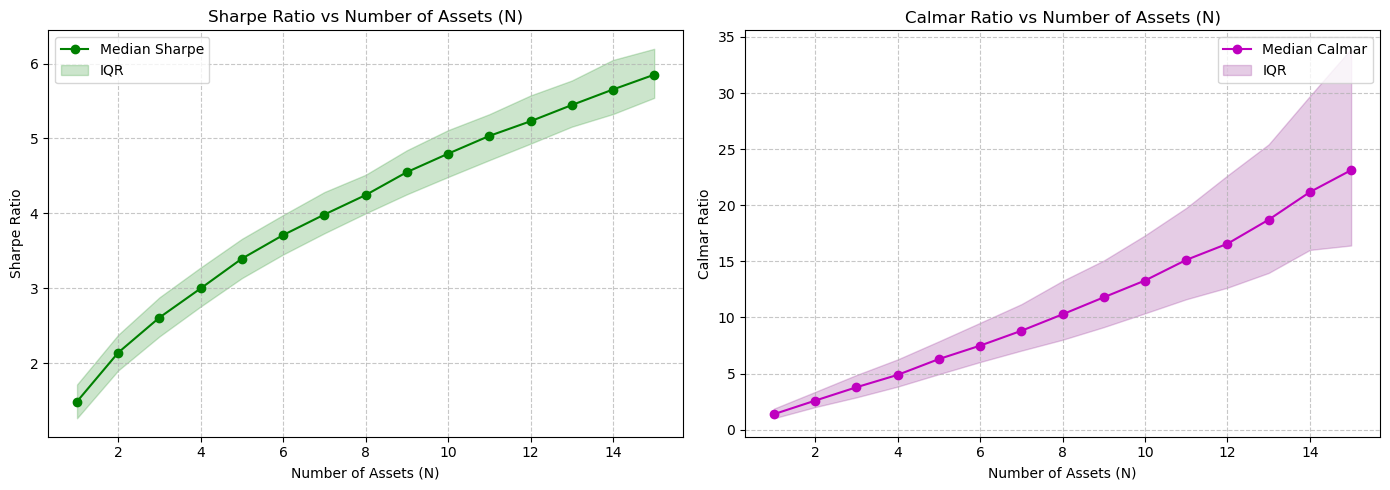

In [2]:
# Create subplots
fig = make_subplots(rows=7, cols=1, 
                    subplot_titles=('Annualized Mean Return vs Number of Assets (N)',
                                    'Annualized Volatility (Std Dev) vs Number of Assets (N)',
                                    'Maximum Drawdown vs Number of Assets (N)',
                                    'Sharpe Ratio vs Number of Assets (N)',
                                    'Calmar Ratio vs Number of Assets (N)',
                                    'Drawdown Recovery Time (Months) vs Number of Assets (N)',
                                    'Percentage of Positive Months vs Number of Assets (N)'),
                    vertical_spacing=0.04)

# 1. Mean Return
fig.add_trace(go.Scatter(x=results['N'], y=results['mean_p50'], mode='lines+markers', name='Median Mean', line=dict(color='blue'), hovertemplate='N: %{x}<br>Mean: %{y:.4f}<extra></extra>'), row=1, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['mean_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=1, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['mean_p25'], mode='lines', fill='tonexty', fillcolor='rgba(0,0,255,0.2)', line=dict(width=0), name='IQR (Mean)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=1, col=1)
fig.add_hline(y=annual_mean*100, line_dash="dash", line_color="black", annotation_text="True Mean", row=1, col=1)

# 2. Volatility
fig.add_trace(go.Scatter(x=results['N'], y=results['std_p50'], mode='lines+markers', name='Median Volatility', line=dict(color='orange'), hovertemplate='N: %{x}<br>Vol: %{y:.4f}<extra></extra>'), row=2, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['std_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=2, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['std_p25'], mode='lines', fill='tonexty', fillcolor='rgba(255,165,0,0.2)', line=dict(width=0), name='IQR (Volatility)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=2, col=1)

# 3. Maximum Drawdown
fig.add_trace(go.Scatter(x=results['N'], y=results['mdd_p50'], mode='lines+markers', name='Median MDD', line=dict(color='red'), hovertemplate='N: %{x}<br>MDD: %{y:.4f}<extra></extra>'), row=3, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['mdd_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=3, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['mdd_p25'], mode='lines', fill='tonexty', fillcolor='rgba(255,0,0,0.2)', line=dict(width=0), name='IQR (MDD)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=3, col=1)

# 4. Sharpe Ratio
fig.add_trace(go.Scatter(x=results['N'], y=results['sharpe_p50'], mode='lines+markers', name='Median Sharpe', line=dict(color='green'), hovertemplate='N: %{x}<br>Sharpe: %{y:.4f}<extra></extra>'), row=4, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['sharpe_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=4, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['sharpe_p25'], mode='lines', fill='tonexty', fillcolor='rgba(0,128,0,0.2)', line=dict(width=0), name='IQR (Sharpe)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=4, col=1)

# 5. Calmar Ratio
fig.add_trace(go.Scatter(x=results['N'], y=results['calmar_p50'], mode='lines+markers', name='Median Calmar', line=dict(color='purple'), hovertemplate='N: %{x}<br>Calmar: %{y:.4f}<extra></extra>'), row=5, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['calmar_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=5, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['calmar_p25'], mode='lines', fill='tonexty', fillcolor='rgba(128,0,128,0.2)', line=dict(width=0), name='IQR (Calmar)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=5, col=1)

# 6. Drawdown Recovery Time
fig.add_trace(go.Scatter(x=results['N'], y=results['dd_time_p50'], mode='lines+markers', name='Median DD Time', line=dict(color='brown'), hovertemplate='N: %{x}<br>DD Time: %{y:.4f}<extra></extra>'), row=6, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['dd_time_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=6, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['dd_time_p25'], mode='lines', fill='tonexty', fillcolor='rgba(165,42,42,0.2)', line=dict(width=0), name='IQR (DD Time)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=6, col=1)


# 7. Percentage of Positive Months
fig.add_trace(go.Scatter(x=results['N'], y=results['pos_months_p50'], mode='lines+markers', name='Median Pos Months', line=dict(color='teal'), hovertemplate='N: %{x}<br>Pos Months: %{y:.2f}%<extra></extra>'), row=7, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['pos_months_p75'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'), row=7, col=1)
fig.add_trace(go.Scatter(x=results['N'], y=results['pos_months_p25'], mode='lines', fill='tonexty', fillcolor='rgba(0,128,128,0.2)', line=dict(width=0), name='IQR (Pos Months)', hovertemplate='N: %{x}<br>25th-75th IQR<extra></extra>'), row=7, col=1)

# Update layout
fig.update_layout(height=2300, width=800, title_text="Monte Carlo Simulation Results", showlegend=True, hovermode='x unified')
fig.update_xaxes(title_text="Number of Assets (N)", row=7, col=1)

# Set common labels
fig.update_yaxes(title_text="Mean Return (%)", row=1, col=1)
fig.update_yaxes(title_text="Volatility (%)", row=2, col=1)
fig.update_yaxes(title_text="Max Drawdown (%)", row=3, col=1)
fig.update_yaxes(title_text="Sharpe Ratio", row=4, col=1)
fig.update_yaxes(title_text="Calmar Ratio", row=5, col=1)
fig.update_yaxes(title_text="Months", row=6, col=1)
fig.update_yaxes(title_text="Positive Months (%)", row=7, col=1)

fig.show()

# Add standard matplotlib plots for Sharpe and Calmar Ratios
plt.figure(figsize=(14, 5))

# Sharpe Ratio Plot
plt.subplot(1, 2, 1)
plt.plot(results['N'], results['sharpe_p50'], 'g-o', label='Median Sharpe')
plt.fill_between(results['N'], results['sharpe_p25'], results['sharpe_p75'], color='green', alpha=0.2, label='IQR')
plt.title('Sharpe Ratio vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Sharpe Ratio')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Calmar Ratio Plot
plt.subplot(1, 2, 2)
plt.plot(results['N'], results['calmar_p50'], 'm-o', label='Median Calmar')
plt.fill_between(results['N'], results['calmar_p25'], results['calmar_p75'], color='purple', alpha=0.2, label='IQR')
plt.title('Calmar Ratio vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Calmar Ratio')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## Standard Python Plots (Matplotlib)

Below are the same plots using standard Matplotlib.

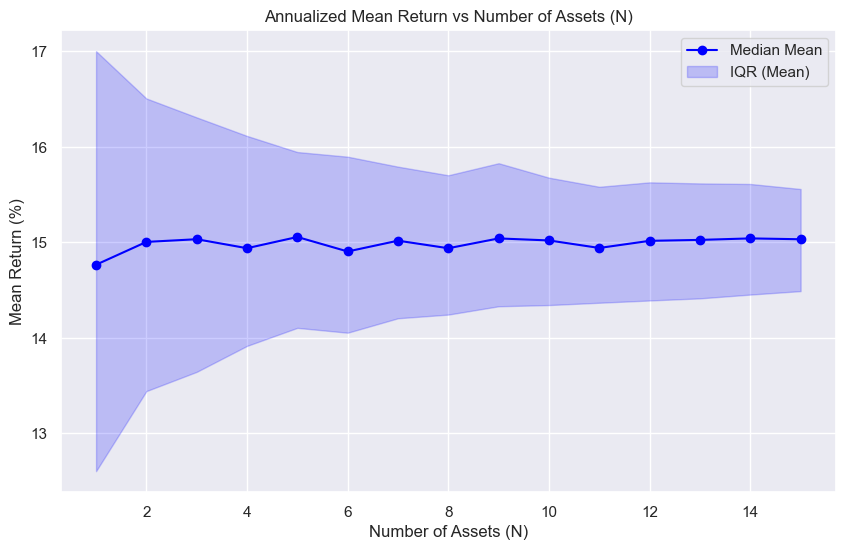

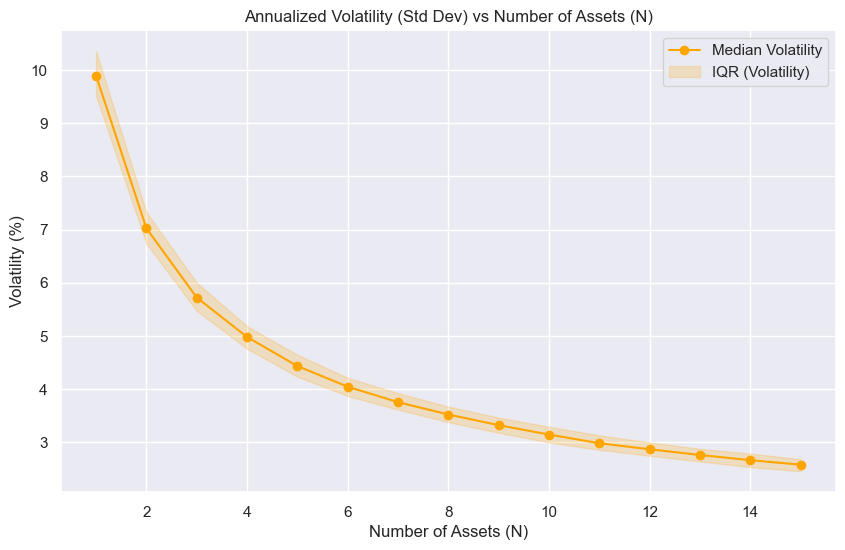

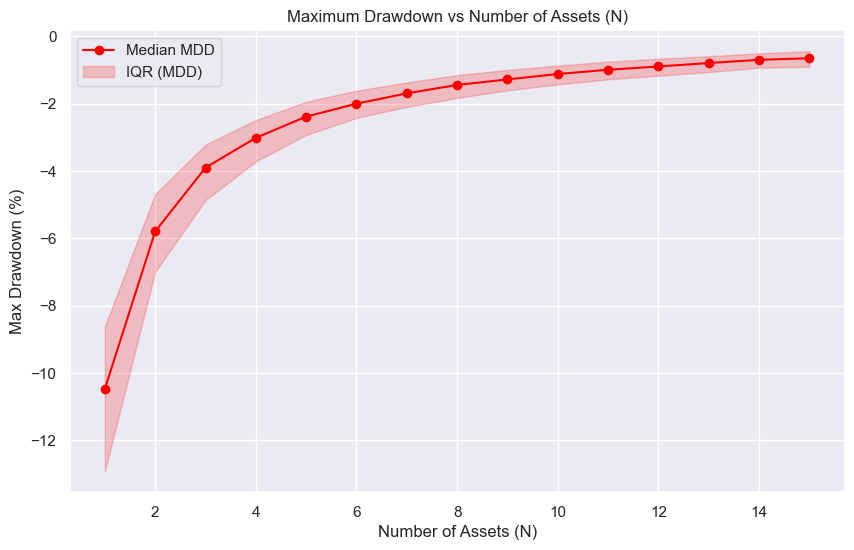

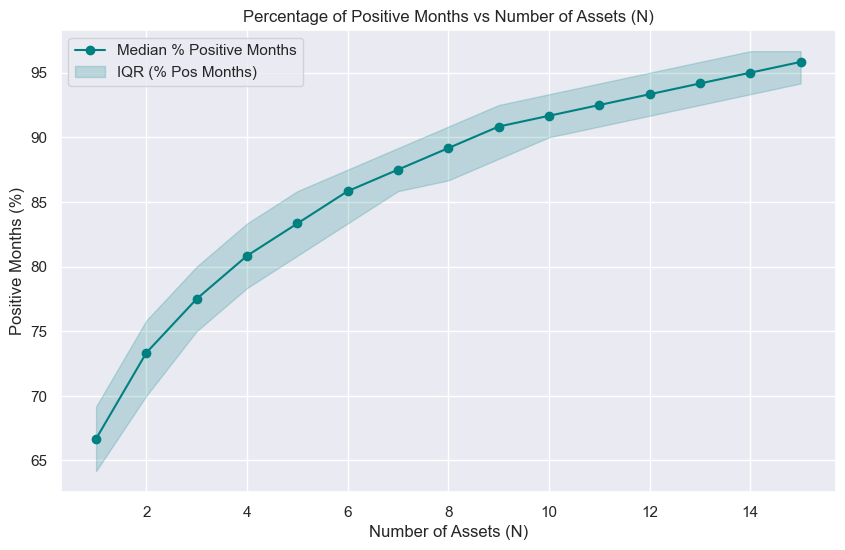

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

# 1. Mean Return
plt.figure(figsize=(10, 6))
plt.plot(results['N'], results['mean_p50'], label='Median Mean', color='blue', marker='o')
plt.fill_between(results['N'], results['mean_p25'], results['mean_p75'], color='blue', alpha=0.2, label='IQR (Mean)')
# plt.axhline(y=annual_mean * 100, color='black', linestyle='--', label=f'True Mean ({annual_mean * 100}%)')
plt.title('Annualized Mean Return vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Mean Return (%)')
plt.legend()
plt.grid(True)
plt.savefig('../../report/educational/educational_easier/Theoretical_vol_vs_N.png', bbox_inches='tight')
plt.show()

# 2. Volatility
plt.figure(figsize=(10, 6))
plt.plot(results['N'], results['std_p50'], label='Median Volatility', color='orange', marker='o')
plt.fill_between(results['N'], results['std_p25'], results['std_p75'], color='orange', alpha=0.2, label='IQR (Volatility)')
plt.title('Annualized Volatility (Std Dev) vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Volatility (%)')
plt.legend()
plt.grid(True)
plt.savefig('../../report/educational/educational_easier/Theoretical_vol_vs_N.png', bbox_inches='tight')
plt.show()

# 3. Maximum Drawdown
plt.figure(figsize=(10, 6))
plt.plot(results['N'], results['mdd_p50'], label='Median MDD', color='red', marker='o')
plt.fill_between(results['N'], results['mdd_p25'], results['mdd_p75'], color='red', alpha=0.2, label='IQR (MDD)')
plt.title('Maximum Drawdown vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Max Drawdown (%)')
plt.legend()
plt.grid(True)
plt.savefig('../../report/educational/educational_easier/Theoretical_vol_vs_N.png', bbox_inches='tight')
plt.show()

# 4. Percentage of Positive Months
plt.figure(figsize=(10, 6))
plt.plot(results['N'], results['pos_months_p50'], label='Median % Positive Months', color='teal', marker='o')
plt.fill_between(results['N'], results['pos_months_p25'], results['pos_months_p75'], color='teal', alpha=0.2, label='IQR (% Pos Months)')
plt.title('Percentage of Positive Months vs Number of Assets (N)')
plt.xlabel('Number of Assets (N)')
plt.ylabel('Positive Months (%)')
plt.legend()
plt.grid(True)
plt.savefig('../../report/educational/educational_easier/Theoretical_pos_months_vs_N.png', bbox_inches='tight')
plt.show()


# Single Asset Drawdown Simulation over Time

In this section, we simulate the performance of a single asset over a 10-year period to observe the evolution of its maximum drawdown. We calculate the maximum drawdown experienced from the start up to each year (1 through 10) across many simulations, and plot the median, 25th percentile, and 75th percentile of these maximum drawdowns over time. As time increases, the expected maximum drawdown generally becomes more severe.

In [4]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Parameters for the single asset
annual_mean_single = 0.25
annual_std_single = 0.18
monthly_mean_single = annual_mean_single / 12
monthly_std_single = annual_std_single / np.sqrt(12)

years = 10
months_per_year = 12
total_months = years * months_per_year
num_sims_single = 1000

# Store the maximum drawdown up to each year for each simulation
# Shape: (num_sims, years)
mdd_over_time = np.zeros((num_sims_single, years))

np.random.seed(42) # For reproducibility

for i in range(num_sims_single):
    # Simulate monthly returns for 10 years
    returns = np.random.normal(monthly_mean_single, monthly_std_single, total_months)
    
    # Calculate cumulative returns
    cum_returns = (1 + returns).cumprod()
    
    # Calculate running maximum
    running_max = np.maximum.accumulate(cum_returns)
    
    # Calculate drawdown at each month
    drawdown = (cum_returns - running_max) / running_max
    
    # For each year (1 to 10), find the minimum drawdown (maximum loss) up to that point
    for y in range(1, years + 1):
        # Months up to the end of year y
        end_month = y * months_per_year
        mdd_over_time[i, y-1] = np.min(drawdown[:end_month]) * 100 # Convert to percentage

# Calculate statistics across simulations for each year
mdd_median = np.median(mdd_over_time, axis=0)
mdd_p25 = np.percentile(mdd_over_time, 25, axis=0)
mdd_p75 = np.percentile(mdd_over_time, 75, axis=0)

year_labels = np.arange(1, years + 1)

# Plotting the evolution of drawdown over time
fig = go.Figure()

# Median
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_median,
    mode='lines+markers',
    name='Median Max Drawdown',
    line=dict(color='red')
))

# 75th percentile (upper bound of IQR for negative numbers, i.e., less severe drawdown)
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_p75,
    mode='lines',
    showlegend=False,
    line=dict(width=0),
    hoverinfo='skip'
))

# 25th percentile (lower bound of IQR for negative numbers, i.e., more severe drawdown)
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_p25,
    mode='lines',
    fill='tonexty',
    fillcolor='rgba(255,0,0,0.2)',
    name='IQR (25th - 75th Percentile)',
    line=dict(width=0)
))

fig.update_layout(
    title='Evolution of Maximum Drawdown Over Time (Single Asset)',
    xaxis_title='Years',
    yaxis_title='Maximum Drawdown (%)',
    hovermode='x unified',
    template='plotly_white',
    xaxis=dict(tickmode='linear', tick0=1, dtick=1)
)

fig.show()

# Portfolio Drawdown Simulation over Time

In this section, we expand our analysis to an equal-weighted portfolio of $N$ independent assets. We simulate the portfolio performance over a 10-year period. Similar to the single asset case, we observe how the expected maximum drawdown evolves over time (from year 1 to year 10). By comparing this with the single asset simulation, we can observe the risk-reduction benefits of diversification over different time horizons.

In [5]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Parameters for the portfolio
N_portfolio = 10 # Number of assets
annual_mean_port = 0.10
annual_std_port = 0.18
monthly_mean_port = annual_mean_port / 12
monthly_std_port = annual_std_port / np.sqrt(12)

years = 10
months_per_year = 12
total_months = years * months_per_year
num_sims_port = 1000

# Store the maximum drawdown up to each year for each simulation
# Shape: (num_sims, years)
mdd_over_time_port = np.zeros((num_sims_port, years))

np.random.seed(42) # For reproducibility

for i in range(num_sims_port):
    # Simulate monthly returns for N independent assets over 10 years
    asset_returns = np.random.normal(monthly_mean_port, monthly_std_port, (total_months, N_portfolio))
    
    # Equal weight portfolio return is the mean across assets for each month
    port_returns = asset_returns.mean(axis=1)
    
    # Calculate cumulative returns
    cum_returns = (1 + port_returns).cumprod()
    
    # Calculate running maximum
    running_max = np.maximum.accumulate(cum_returns)
    
    # Calculate drawdown at each month
    drawdown = (cum_returns - running_max) / running_max
    
    # For each year (1 to 10), find the minimum drawdown (maximum loss) up to that point
    for y in range(1, years + 1):
        # Months up to the end of year y
        end_month = y * months_per_year
        mdd_over_time_port[i, y-1] = np.min(drawdown[:end_month]) * 100 # Convert to percentage

# Calculate statistics across simulations for each year
mdd_median_port = np.median(mdd_over_time_port, axis=0)
mdd_p25_port = np.percentile(mdd_over_time_port, 25, axis=0)
mdd_p75_port = np.percentile(mdd_over_time_port, 75, axis=0)

year_labels = np.arange(1, years + 1)

# Plotting the evolution of drawdown over time
fig = go.Figure()

# Median
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_median_port,
    mode='lines+markers',
    name=f'Median Max Drawdown (N={N_portfolio})',
    line=dict(color='blue')
))

# 75th percentile (upper bound of IQR for negative numbers, i.e., less severe drawdown)
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_p75_port,
    mode='lines',
    showlegend=False,
    line=dict(width=0),
    hoverinfo='skip'
))

# 25th percentile (lower bound of IQR for negative numbers, i.e., more severe drawdown)
fig.add_trace(go.Scatter(
    x=year_labels, y=mdd_p25_port,
    mode='lines',
    fill='tonexty',
    fillcolor='rgba(0,0,255,0.2)',
    name='IQR (25th - 75th Percentile)',
    line=dict(width=0)
))

fig.update_layout(
    title=f'Evolution of Maximum Drawdown Over Time (Portfolio of {N_portfolio} Assets)',
    xaxis_title='Years',
    yaxis_title='Maximum Drawdown (%)',
    hovermode='x unified',
    template='plotly_white',
    xaxis=dict(tickmode='linear', tick0=1, dtick=1)
)

fig.show()

# Spurious Correlation Simulation & ECDF Analysis in Small Samples ($T=24, N=30$)

In this section, we analyze empirical correlation matrices estimated from limited sample periods ($T = 24$ months, i.e., 2 years) across an asset universe of $N = 30$ assets.

### Quantitative Finance Context & Theoretical Motivation:
1. **Underlying Data Generating Process**:
   - All 30 assets are generated from **mutually independent** Gaussian distributions with annualized mean return $\mu = 20\%$ and annualized volatility $\sigma = 10\%$ (monthly parameters: $\mu_m = 20\% / 12$, $\sigma_m = 10\% / \sqrt{12}$).
   - *Parameter Scale Invariance*: The sample Pearson correlation coefficient $r_{ij} = \frac{\sum (X_{it} - \bar{X}_i)(X_{jt} - \bar{X}_j)}{\sqrt{\sum(X_{it}-\bar{X}_i)^2 \sum(X_{jt}-\bar{X}_j)^2}}$ is strictly invariant to affine transformations ($X \mapsto aX + b$ for $a > 0$). Therefore, the correlation structure of independent assets depends entirely on sample length $T$, regardless of $\mu$ and $\sigma$.
2. **Spurious Correlations & Small Sample Estimation Noise**:
   - The true underlying population correlation is zero for all distinct pairs: $\rho_{ij} = 0, \forall i \neq j$.
   - However, with only $T = 24$ historical observations, the standard error of sample correlation under $H_0: \rho = 0$ is approximately:
     $$\text{SE}(r) \approx \frac{1}{\sqrt{T}} = \frac{1}{\sqrt{24}} \approx 0.2041$$
   - Consequently, for any pair of independent assets, sample correlations regularly reach $\pm 0.30, \pm 0.40$ or even higher purely by random chance.
3. **Rank Deficiency & The Curse of Dimensionality ($N > T$)**:
   - With $N = 30$ assets and only $T = 24$ periods, the sample covariance and correlation matrices are singular with rank at most $T - 1 = 23$.
   - There are at least $30 - 23 = 7$ exact zero eigenvalues. In classical Markowitz mean-variance optimization, inverting the covariance matrix $\mathbf{\Sigma}^{-1}$ is impossible without shrinkage (e.g. Ledoit-Wolf) or factor dimensionality reduction.
4. **Exact Theoretical Distribution of Sample Correlations**:
   - Under the null hypothesis of independence between normal variables, the sample correlation coefficient $r$ transforms to Student's $t$ with $T - 2$ degrees of freedom:
     $$t = r \sqrt{\frac{T - 2}{1 - r^2}} \sim t(T - 2 = 22)$$
   - The exact theoretical cumulative distribution function (CDF) for $r \in (-1, 1)$ is given by:
     $$F_{\text{theoretical}}(r) = F_{t(22)}\left( r \sqrt{\frac{22}{1 - r^2}} \right)$$
   - We evaluate the Empirical Cumulative Distribution Function (ECDF) of all distinct off-diagonal pairs ($N(N-1)/2 = 435$ correlations) against this theoretical benchmark.

In [6]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.special import gammaln
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set random seed for reproducibility
np.random.seed(42)

# Simulation parameters
N_assets = 30         # 30 assets
T_months = 24         # 24 months of historical track record
annual_mean = 0.20    # 20% annualized return
annual_std = 0.10     # 10% annualized volatility

# Convert to monthly parameters
monthly_mean = annual_mean / 12
monthly_std = annual_std / np.sqrt(12)

# Simulate independent Gaussian monthly returns: shape (24, 30)
sim_returns = np.random.normal(monthly_mean, monthly_std, size=(T_months, N_assets))
asset_names = [f"Asset_{i+1:02d}" for i in range(N_assets)]
df_returns = pd.DataFrame(sim_returns, columns=asset_names)

# Compute sample Pearson correlation matrix
corr_matrix = df_returns.corr()

# Extract distinct off-diagonal pairwise correlations (upper triangle, k=1)
triu_indices = np.triu_indices(N_assets, k=1)
pairwise_corrs = corr_matrix.values[triu_indices]

# Compute matrix properties
matrix_rank = np.linalg.matrix_rank(corr_matrix.values)
eigenvals = np.linalg.eigvalsh(corr_matrix.values)
zero_eigenvals = np.sum(np.isclose(eigenvals, 0, atol=1e-8))

print("=" * 70)
print(f"CORRELATION MATRIX SUMMARY (N={N_assets} assets, T={T_months} months)")
print("=" * 70)
print(f"Total distinct pairwise correlations:    {len(pairwise_corrs)}")
print(f"True Population Correlation (Null):     0.0000")
print(f"Empirical Mean Correlation:              {np.mean(pairwise_corrs):+.4f}")
print(f"Empirical Std of Correlation:            {np.std(pairwise_corrs):.4f} (Theoretical 1/sqrt(24) = {1/np.sqrt(T_months):.4f})")
print(f"Empirical Median Correlation:           {np.median(pairwise_corrs):+.4f}")
print(f"Minimum Correlation observed:           {np.min(pairwise_corrs):+.4f}")
print(f"Maximum Correlation observed:           {np.max(pairwise_corrs):+.4f}")
print(f"Interquartile Range [p25, p75]:          [{np.percentile(pairwise_corrs, 25):+.4f}, {np.percentile(pairwise_corrs, 75):+.4f}]")
print(f"90% Range [p05, p95]:                    [{np.percentile(pairwise_corrs, 5):+.4f}, {np.percentile(pairwise_corrs, 95):+.4f}]")
print(f"Pairs with |corr| > 0.30:                {(np.abs(pairwise_corrs) > 0.30).sum()} ({ (np.abs(pairwise_corrs) > 0.30).mean()*100:.1f}%)")
print(f"Pairs with |corr| > 0.40:                {(np.abs(pairwise_corrs) > 0.40).sum()} ({ (np.abs(pairwise_corrs) > 0.40).mean()*100:.1f}%)")
print(f"Pairs with |corr| > 0.50:                {(np.abs(pairwise_corrs) > 0.50).sum()} ({ (np.abs(pairwise_corrs) > 0.50).mean()*100:.1f}%)")
print("-" * 70)
print(f"Matrix Rank:                             {matrix_rank} (Max theoretical rank: {min(T_months - 1, N_assets)})")
print(f"Zero / Singular Eigenvalues:             {zero_eigenvals} of {N_assets} (Matrix is singular & non-invertible!)")
print("=" * 70)


CORRELATION MATRIX SUMMARY (N=30 assets, T=24 months)
Total distinct pairwise correlations:    435
True Population Correlation (Null):     0.0000
Empirical Mean Correlation:              -0.0052
Empirical Std of Correlation:            0.2064 (Theoretical 1/sqrt(24) = 0.2041)
Empirical Median Correlation:           -0.0085
Minimum Correlation observed:           -0.7983
Maximum Correlation observed:           +0.4922
Interquartile Range [p25, p75]:          [-0.1456, +0.1200]
90% Range [p05, p95]:                    [-0.3409, +0.3532]
Pairs with |corr| > 0.30:                68 (15.6%)
Pairs with |corr| > 0.40:                24 (5.5%)
Pairs with |corr| > 0.50:                2 (0.5%)
----------------------------------------------------------------------
Matrix Rank:                             23 (Max theoretical rank: 23)
Zero / Singular Eigenvalues:             7 of 30 (Matrix is singular & non-invertible!)


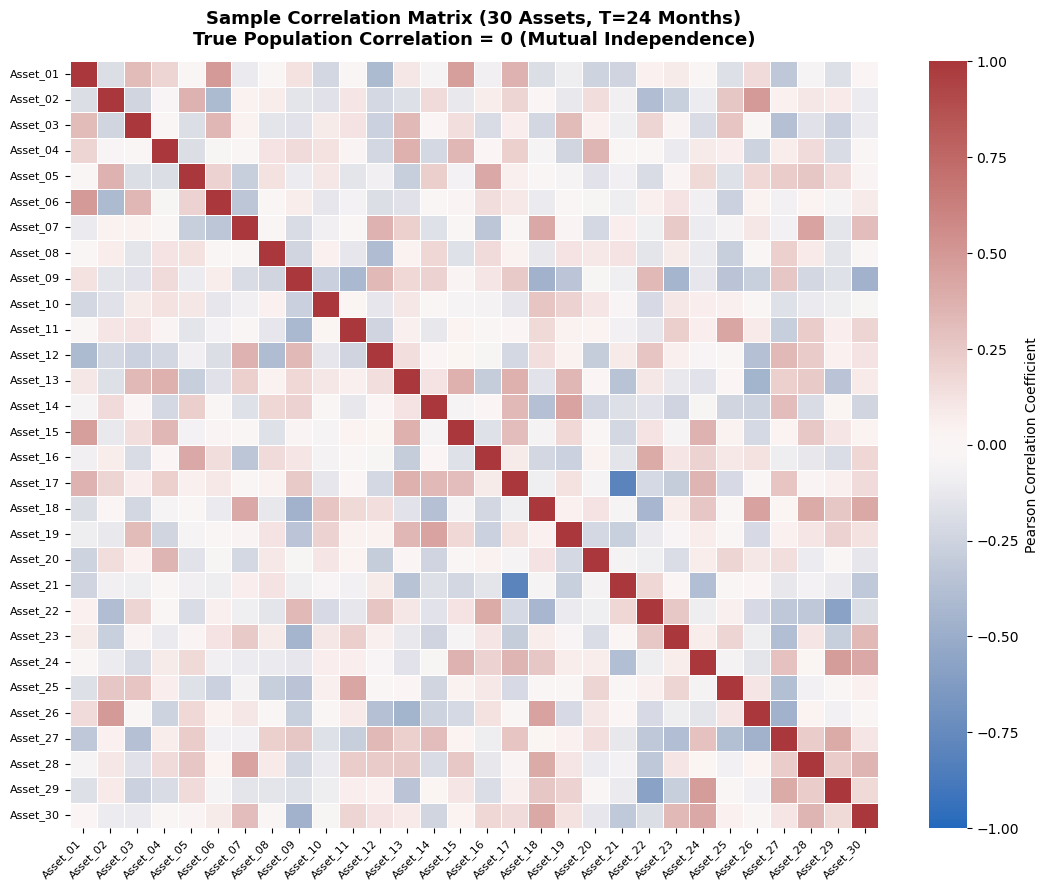

In [7]:
# 2. Visualize the Correlation Matrix (Plotly Interactive & Seaborn)

# Interactive Plotly Heatmap
fig_heat = go.Figure(data=go.Heatmap(
    z=corr_matrix.values,
    x=asset_names,
    y=asset_names,
    colorscale='RdBu_r',
    zmid=0.0,
    zmin=-1.0,
    zmax=1.0,
    colorbar=dict(title='Correlation', tickvals=[-1.0, -0.5, 0.0, 0.5, 1.0]),
    hovertemplate='Asset X: %{x}<br>Asset Y: %{y}<br>Correlation: %{z:.3f}<extra></extra>'
))

fig_heat.update_layout(
    title=dict(
        text=f'Sample Correlation Matrix: {N_assets} Independent Assets (T={T_months} Months)<br><sup>Notice spurious non-zero correlations arising from pure sampling noise</sup>',
        x=0.5
    ),
    xaxis=dict(tickangle=-45, tickfont=dict(size=9)),
    yaxis=dict(autorange='reversed', tickfont=dict(size=9)),
    width=800,
    height=750,
    template='plotly_white'
)

fig_heat.show()

# High-resolution Seaborn Heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title(f'Sample Correlation Matrix ({N_assets} Assets, T={T_months} Months)
True Population Correlation = 0 (Mutual Independence)', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


Kolmogorov-Smirnov Test vs Theoretical Student-t (df=22):
  KS Statistic D = 0.0458, p-value = 0.3120
  -> Fail to reject null: Empirical correlations are statistically consistent with pure independent Gaussian noise.


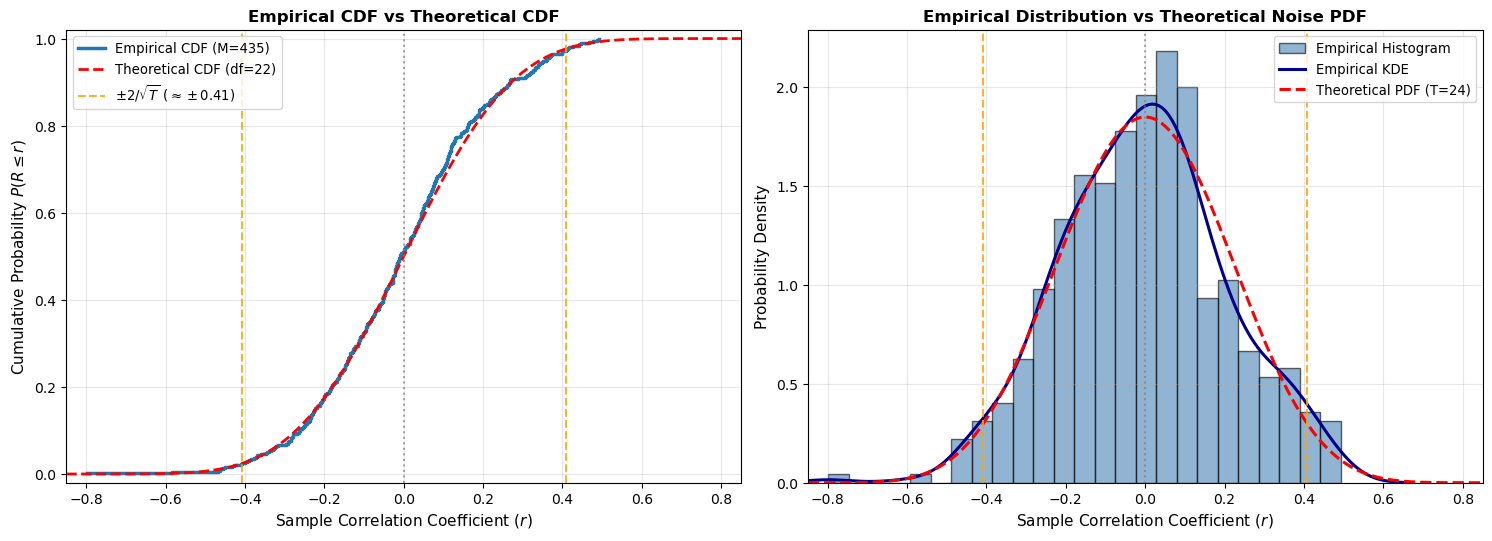

In [8]:
# 3. ECDF and Distribution of Sample Correlations vs Theoretical Null Distribution

# Sort correlations to build the Empirical Cumulative Distribution Function (ECDF)
sorted_r = np.sort(pairwise_corrs)
M_pairs = len(sorted_r)
ecdf_vals = np.arange(1, M_pairs + 1) / M_pairs

# Theoretical Null Distribution (Student-t with df = T - 2)
df_t = T_months - 2  # 24 - 2 = 22 degrees of freedom
r_grid = np.linspace(-0.85, 0.85, 400)
t_grid = r_grid * np.sqrt(df_t) / np.sqrt(np.maximum(1 - r_grid**2, 1e-12))
theoretical_cdf = stats.t.cdf(t_grid, df=df_t)

# Exact theoretical probability density function (PDF)
th_pdf = (1.0 / np.sqrt(np.pi)) * np.exp(gammaln((T_months - 1) / 2) - gammaln((T_months - 2) / 2)) * (1 - r_grid**2)**((T_months - 4) / 2)

# Kolmogorov-Smirnov Test comparing empirical sample to theoretical distribution
t_stats_sample = sorted_r * np.sqrt(df_t) / np.sqrt(np.maximum(1 - sorted_r**2, 1e-12))
ks_stat, ks_pval = stats.kstest(t_stats_sample, 't', args=(df_t,))

print(f"Kolmogorov-Smirnov Test vs Theoretical Student-t (df={df_t}):")
print(f"  KS Statistic D = {ks_stat:.4f}, p-value = {ks_pval:.4f}")
if ks_pval > 0.05:
    print("  -> Fail to reject null: Empirical correlations are statistically consistent with pure independent Gaussian noise.")
else:
    print("  -> Significant departure from null.")

# Interactive Plotly ECDF
fig_ecdf = go.Figure()

# ECDF step curve
fig_ecdf.add_trace(go.Scatter(
    x=sorted_r, y=ecdf_vals,
    mode='lines',
    line_shape='hv',
    name=f'Empirical CDF ({M_pairs} pairs)',
    line=dict(color='blue', width=2.5)
))

# Theoretical CDF
fig_ecdf.add_trace(go.Scatter(
    x=r_grid, y=theoretical_cdf,
    mode='lines',
    name=f'Theoretical CDF under H0 (df={df_t})',
    line=dict(color='crimson', width=2, dash='dash')
))

# Reference lines
se_corr = 1.0 / np.sqrt(T_months)
fig_ecdf.add_vline(x=0, line_dash='solid', line_color='gray', opacity=0.5)
fig_ecdf.add_vline(x=-2 * se_corr, line_dash='dot', line_color='orange', annotation_text='-2/√T (-0.408)', annotation_position='top left')
fig_ecdf.add_vline(x=2 * se_corr, line_dash='dot', line_color='orange', annotation_text='+2/√T (+0.408)', annotation_position='bottom right')

fig_ecdf.update_layout(
    title=dict(
        text=f'Empirical Cumulative Distribution Function (ECDF) of Pairwise Correlations<br><sup>N={N_assets} Assets, T={T_months} Months (Sample size M={M_pairs} correlation coefficients)</sup>',
        x=0.5
    ),
    xaxis_title='Sample Pearson Correlation Coefficient (r)',
    yaxis_title='Cumulative Probability P(R ≤ r)',
    template='plotly_white',
    hovermode='x unified',
    width=850,
    height=550
)

fig_ecdf.show()

# Static Dual-Panel Matplotlib Figure (ECDF + Density / Histogram)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: ECDF vs Theoretical CDF
ax1.step(sorted_r, ecdf_vals, where='post', label=f'Empirical CDF (M={M_pairs})', color='#1f77b4', lw=2.5)
ax1.plot(r_grid, theoretical_cdf, 'r--', label=f'Theoretical CDF (df={df_t})', lw=2)
ax1.axvline(0, color='gray', linestyle=':', alpha=0.7)
ax1.axvline(-2 * se_corr, color='orange', linestyle='--', alpha=0.85, label=r'$\pm 2/\sqrt{T}$ ($pprox \pm 0.41$)')
ax1.axvline(2 * se_corr, color='orange', linestyle='--', alpha=0.85)
ax1.set_xlabel('Sample Correlation Coefficient ($r$)', fontsize=11)
ax1.set_ylabel('Cumulative Probability $P(R \leq r)$', fontsize=11)
ax1.set_title('Empirical CDF vs Theoretical CDF', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', fontsize=9.5)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(-0.85, 0.85)
ax1.set_ylim(-0.02, 1.02)

# Panel 2: Histogram & KDE vs Theoretical PDF
ax2.hist(pairwise_corrs, bins=25, density=True, alpha=0.6, color='#4682b4', edgecolor='black', label='Empirical Histogram')
sns.kdeplot(pairwise_corrs, ax=ax2, color='#00008b', lw=2.2, label='Empirical KDE')
ax2.plot(r_grid, th_pdf, 'r--', lw=2.2, label=f'Theoretical PDF (T={T_months})')
ax2.axvline(0, color='gray', linestyle=':', alpha=0.7)
ax2.axvline(-2 * se_corr, color='orange', linestyle='--', alpha=0.85)
ax2.axvline(2 * se_corr, color='orange', linestyle='--', alpha=0.85)
ax2.set_xlabel('Sample Correlation Coefficient ($r$)', fontsize=11)
ax2.set_ylabel('Probability Density', fontsize=11)
ax2.set_title('Empirical Distribution vs Theoretical Noise PDF', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9.5)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(-0.85, 0.85)

plt.tight_layout()
plt.show()


### Monte Carlo Ensemble Simulation: ECDF Sampling Distribution

To confirm that the broad dispersion of correlation coefficients is not an idiosyncrasy of a single random seed, we now perform a **Monte Carlo ensemble simulation** over $B = 500$ independent trials of 24-month return series for the 30 assets.

For each trial, we compute the sample correlation matrix and evaluate the ECDF across a fixed grid $r \in [-0.85, 0.85]$. This allows us to observe:
1. The **Median ECDF** across all trials (which converges to the exact theoretical curve).
2. The **90% Confidence Envelope (5th to 95th percentiles)** of empirical CDFs, illustrating the range of sample variation an allocator should anticipate when evaluating 2-year correlation matrices.

In [9]:
# 4. Monte Carlo Simulation of ECDFs across 500 Independent Realizations

num_trials = 500
r_eval_grid = np.linspace(-0.85, 0.85, 200)

# Evaluate theoretical CDF on the grid
t_eval_grid = r_eval_grid * np.sqrt(df_t) / np.sqrt(np.maximum(1 - r_eval_grid**2, 1e-12))
th_cdf_grid = stats.t.cdf(t_eval_grid, df=df_t)

trial_ecdfs = np.zeros((num_trials, len(r_eval_grid)))
max_corrs_mc = np.zeros(num_trials)
min_corrs_mc = np.zeros(num_trials)

print(f"Running Monte Carlo Simulation ({num_trials} trials of T={T_months}, N={N_assets})...")

for b in range(num_trials):
    # Simulate independent Gaussian returns
    ret_b = np.random.normal(monthly_mean, monthly_std, size=(T_months, N_assets))
    corr_b = np.corrcoef(ret_b, rowvar=False)
    corrs_b = corr_b[triu_indices]
    
    # Store extreme correlations
    max_corrs_mc[b] = np.max(corrs_b)
    min_corrs_mc[b] = np.min(corrs_b)
    
    # Calculate ECDF on evaluation grid
    trial_ecdfs[b, :] = np.searchsorted(np.sort(corrs_b), r_eval_grid, side='right') / len(corrs_b)

# Calculate percentiles across Monte Carlo runs
ecdf_p50 = np.percentile(trial_ecdfs, 50, axis=0)
ecdf_p05 = np.percentile(trial_ecdfs, 5, axis=0)
ecdf_p95 = np.percentile(trial_ecdfs, 95, axis=0)

print("Monte Carlo Simulation completed!")
print(f"Average Minimum Correlation across 500 trials: {np.mean(min_corrs_mc):+.4f} (median: {np.median(min_corrs_mc):+.4f})")
print(f"Average Maximum Correlation across 500 trials: {np.mean(max_corrs_mc):+.4f} (median: {np.median(max_corrs_mc):+.4f})")
print(f"Max absolute discrepancy between MC Median ECDF and Theoretical CDF: {np.max(np.abs(ecdf_p50 - th_cdf_grid)):.4f}")

# Plotly Monte Carlo Ensemble Chart
fig_mc = go.Figure()

# 90% confidence ribbon
fig_mc.add_trace(go.Scatter(
    x=r_eval_grid, y=ecdf_p95,
    mode='lines',
    line=dict(width=0),
    showlegend=False,
    hoverinfo='skip'
))

fig_mc.add_trace(go.Scatter(
    x=r_eval_grid, y=ecdf_p05,
    mode='lines',
    fill='tonexty',
    fillcolor='rgba(31, 119, 180, 0.25)',
    name='90% MC Simulation Band (5th - 95th %ile)',
    line=dict(width=0)
))

# Median ECDF
fig_mc.add_trace(go.Scatter(
    x=r_eval_grid, y=ecdf_p50,
    mode='lines',
    name=f'Median ECDF ({num_trials} trials)',
    line=dict(color='#1f77b4', width=2.5)
))

# Exact Theoretical CDF
fig_mc.add_trace(go.Scatter(
    x=r_eval_grid, y=th_cdf_grid,
    mode='lines',
    name=f'Theoretical CDF (df={df_t})',
    line=dict(color='crimson', width=2, dash='dash')
))

fig_mc.add_vline(x=0, line_dash='solid', line_color='gray', opacity=0.5)
fig_mc.add_vline(x=-2 * se_corr, line_dash='dot', line_color='orange')
fig_mc.add_vline(x=2 * se_corr, line_dash='dot', line_color='orange')

fig_mc.update_layout(
    title=dict(
        text=f'Monte Carlo ECDF Distribution over {num_trials} Trials (T={T_months} Months, N={N_assets} Assets)<br><sup>Empirical convergence to theoretical Student-t distribution under mutual independence</sup>',
        x=0.5
    ),
    xaxis_title='Sample Correlation Coefficient (r)',
    yaxis_title='Cumulative Probability',
    template='plotly_white',
    hovermode='x unified',
    width=850,
    height=550
)

fig_mc.show()


Running Monte Carlo Simulation (500 trials of T=24, N=30)...
Monte Carlo Simulation completed!
Average Minimum Correlation across 500 trials: -0.5852 (median: -0.5839)
Average Maximum Correlation across 500 trials: +0.5827 (median: +0.5777)
Max absolute discrepancy between MC Median ECDF and Theoretical CDF: 0.0038


In [10]:
!sh ../../report/educational/educational_easier/compile_report.sh

Generated table_fund_stats.tex
Generated table_lazarus_stats.tex
Generated table_lazarus_monthly.tex
This is pdfTeX, Version 3.141592653-2.6-1.40.26 (TeX Live 2024) (preloaded format=pdflatex)
 restricted \write18 enabled.
entering extended mode
(./fof_report.tex
LaTeX2e <2024-11-01> patch level 1
L3 programming layer <2024-11-02>
(/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/latex/base/article.cls
Document Class: article 2024/06/29 v1.4n Standard LaTeX document class
(/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/latex/base/size11.clo)) (/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/latex/base/inputenc.sty) (/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/latex/geometry/geometry.sty (/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/latex/graphics/keyval.sty) (/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/generic/iftex/ifvtex.sty (/Users/arthurdhonneur/Library/TinyTeX/texmf-dist/tex/generic/iftex/iftex.sty))) (/Users/arthurdhonneur/Library/TinyTeX/